# F-measure của các bài tập cơ bản

## Bài tập thêm 2 — Trang 32

### Yêu cầu

Tính F-measure = 2 × precision × recall / (precision + recall) cho các phương pháp phân lớp trong hai bài tập cơ bản: doanh số đồ chơi (trang 24–25) và cảm xúc (trang 25–26).

### Dữ liệu và phương pháp

Dùng nguyên bảng và các mẫu kiểm thử trong đề. Đồ chơi sử dụng cây ID3 và Naïve Bayes với làm trơn Laplace; cảm xúc sử dụng CART và Naïve Bayes. Chỉ xây dựng những mô hình và phép đánh giá cần để tính F-measure. Thuộc tính phân loại được giữ dưới dạng giá trị rời rạc, không thay khoảng tần suất bằng giá trị trung điểm.

ID3 chọn thuộc tính có information gain lớn nhất. Cây Gini chọn thuộc tính có Gini sau chia nhỏ nhất và tạo nhánh theo từng giá trị, đúng cách minh họa phần cơ bản trang 7–9. Trường hợp hòa chọn thuộc tính xuất hiện trước; nhãn đa số hòa được chọn theo thứ tự chữ. Naïve Bayes dùng Laplace alpha=1 cho cả xác suất lớp và xác suất điều kiện theo ví dụ hướng dẫn. Các chỉ số được tính theo từng lớp; trình bày thêm trung bình macro của F1 từng lớp. Nếu mẫu số bằng 0, quy ước chỉ số bằng 0 và hiển thị số mẫu/dự đoán tương ứng.

In [1]:
print("Đặng Ngọc Hiếu - 6451071024")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
sns.set_theme(style="whitegrid", font="DejaVu Sans")
pd.set_option("display.max_columns", None)

# Chép đúng 15 dòng bảng đồ chơi, trang 24.
toys = pd.DataFrame([
    ["Điều khiển","3","Nhỏ","Nhựa PP","Cao"],
    ["Xếp hình","5","Vừa","Cao su","Thấp"],
    ["Xếp hình","7","To","Nhựa PP","Thấp"],
    ["Điều khiển","5","Nhỏ","Cao su","Thấp"],
    ["Búp bê","3","Vừa","Nhựa PP","Thấp"],
    ["Điều khiển","5","Vừa","Nhựa PP","Cao"],
    ["Búp bê","5","To","Nhựa PP","Cao"],
    ["Điều khiển","7","Vừa","Cao su","Thấp"],
    ["Xếp hình","7","To","Cao su","Cao"],
    ["Xếp hình","3","To","Nhựa PP","Thấp"],
    ["Búp bê","3","Nhỏ","Cao su","Thấp"],
    ["Xếp hình","3","Nhỏ","Nhựa PP","Cao"],
    ["Điều khiển","5","To","Cao su","Thấp"],
    ["Búp bê","5","Vừa","Nhựa PP","Cao"],
    ["Búp bê","7","To","Nhựa PP","Cao"],
], columns=["Loại","Số màu","Kích thước","Chất liệu","Doanh số bán"])
toys_test = pd.DataFrame([
    ["Búp bê","3","To","Cao su"],
    ["Xếp hình","5","To","Nhựa PP"],
    ["Điều khiển","3","Vừa","Cao su"],
], columns=toys.columns[:-1])
toys_actual = ["Thấp","Thấp","Cao"]

# Chép đúng 14 dòng bảng cảm xúc, trang 25; giữ nguyên các khoảng đếm.
sentiment = pd.DataFrame([
    ["0..5","11..20",">20","11..20",">20","0..5","tốt"],
    ["11..20","6..10","6..10","0..5","11..20","11..20","tốt"],
    ["6..10","0..5","6..10","11..20","0..5","6..10","xấu"],
    [">20","0..5","11..20","6..10","0..5",">20","bình thường"],
    ["0..5",">20","11..20","0..5","6..10","0..5","xấu"],
    ["0..5","6..10","0..5","0..5","11..20","11..20","xấu"],
    ["0..5","6..10","11..20","0..5","6..10","0..5","tốt"],
    ["11..20",">20","0..5","11..20","0..5","11..20","bình thường"],
    ["0..5","0..5","6..10","6..10","6..10",">20","tốt"],
    ["11..20","0..5","11..20","11..20","0..5","11..20","tốt"],
    [">20","6..10","0..5","0..5","0..5","6..10","xấu"],
    ["0..5","0..5","11..20","0..5","11..20",">20","bình thường"],
    ["6..10","11..20","6..10",">20","0..5","6..10","bình thường"],
    ["11..20","6..10",">20","11..20","0..5","0..5","xấu"],
], columns=["giảm","người","chuyển","yêu","vừa","đi","Cảm xúc"])
sentiment_test = pd.DataFrame([
    ["0..5","6..10","0..5","11..20","6..10","0..5"],
    ["0..5","0..5","6..10","0..5","11..20",">20"],
    ["6..10","0..5","11..20",">20","6..10","6..10"],
    ["6..10","11..20","6..10","6..10",">20","0..5"],
], columns=sentiment.columns[:-1])
sentiment_actual = ["xấu","tốt","bình thường","tốt"]
display(toys, toys_test.assign(Thực_tế=toys_actual))
display(sentiment, sentiment_test.assign(Thực_tế=sentiment_actual))


Đặng Ngọc Hiếu - 6451071024


,Loại,Số màu,Kích thước,Chất liệu,Doanh số bán
0,Điều khiển,3,Nhỏ,Nhựa PP,Cao
1,Xếp hình,5,Vừa,Cao su,Thấp
2,Xếp hình,7,To,Nhựa PP,Thấp
3,Điều khiển,5,Nhỏ,Cao su,Thấp
4,Búp bê,3,Vừa,Nhựa PP,Thấp
5,Điều khiển,5,Vừa,Nhựa PP,Cao
6,Búp bê,5,To,Nhựa PP,Cao
7,Điều khiển,7,Vừa,Cao su,Thấp
8,Xếp hình,7,To,Cao su,Cao
9,Xếp hình,3,To,Nhựa PP,Thấp


,Loại,Số màu,Kích thước,Chất liệu,Thực_tế
0,Búp bê,3,To,Cao su,Thấp
1,Xếp hình,5,To,Nhựa PP,Thấp
2,Điều khiển,3,Vừa,Cao su,Cao


,giảm,người,chuyển,yêu,vừa,đi,Cảm xúc
0,0..5,11..20,>20,11..20,>20,0..5,tốt
1,11..20,6..10,6..10,0..5,11..20,11..20,tốt
2,6..10,0..5,6..10,11..20,0..5,6..10,xấu
3,>20,0..5,11..20,6..10,0..5,>20,bình thường
4,0..5,>20,11..20,0..5,6..10,0..5,xấu
5,0..5,6..10,0..5,0..5,11..20,11..20,xấu
6,0..5,6..10,11..20,0..5,6..10,0..5,tốt
7,11..20,>20,0..5,11..20,0..5,11..20,bình thường
8,0..5,0..5,6..10,6..10,6..10,>20,tốt
9,11..20,0..5,11..20,11..20,0..5,11..20,tốt


,giảm,người,chuyển,yêu,vừa,đi,Thực_tế
0,0..5,6..10,0..5,11..20,6..10,0..5,xấu
1,0..5,0..5,6..10,0..5,11..20,>20,tốt
2,6..10,0..5,11..20,>20,6..10,6..10,bình thường
3,6..10,11..20,6..10,6..10,>20,0..5,tốt


In [2]:
print("Đặng Ngọc Hiếu - 6451071024")

def impurity(labels, criterion):
    probabilities = labels.value_counts(normalize=True).to_numpy()
    if criterion == "entropy":
        return -np.sum(probabilities * np.log2(probabilities))
    return 1 - np.sum(probabilities ** 2)

def build_tree(frame, target, criterion="entropy", attributes=None):
    if attributes is None:
        attributes = [c for c in frame.columns if c != target]
    node = {"majority": frame[target].mode().iloc[0]}
    if frame[target].nunique() == 1:
        return node
    scores = {}
    for column in attributes:
        if frame[column].nunique() < 2:
            continue
        score = 0.0
        for value in sorted(frame[column].unique()):
            subset = frame.loc[frame[column].eq(value)]
            score += len(subset) / len(frame) * impurity(subset[target], criterion)
        scores[column] = score
    if not scores:
        return node
    # Entropy sau chia nhỏ nhất tương đương information gain lớn nhất.
    # Với Gini, chia từng giá trị như ví dụ của PDF trang 7–9.
    best = min(scores, key=scores.get)
    remaining = [c for c in attributes if c != best]
    node["column"] = best
    node["children"] = {
        value: build_tree(frame.loc[frame[best].eq(value)], target, criterion, remaining)
        for value in sorted(frame[best].unique())
    }
    return node

def predict_tree(node, row):
    while "column" in node:
        child = node["children"].get(row[node["column"]])
        if child is None:
            return node["majority"]
        node = child
    return node["majority"]

def predict_bayes(frame, target, test):
    classes = sorted(frame[target].unique())
    features = [c for c in frame if c != target]
    domains = {c:set(frame[c]) for c in features}
    if any(not set(test[c]).issubset(domains[c]) for c in features):
        raise ValueError("Mẫu kiểm thử có giá trị ngoài miền thuộc tính của bảng đề.")
    scores = []
    for _,row in test.iterrows():
        row_scores = []
        for label in classes:
            subset = frame.loc[frame[target].eq(label)]
            # Làm trơn cả prior và likelihood theo ví dụ Laplace trang 12.
            score = np.log((len(subset)+1)/(len(frame)+len(classes)))
            for column in features:
                count = subset[column].eq(row[column]).sum()
                score += np.log((count+1)/(len(subset)+len(domains[column])))
            row_scores.append(score)
        scores.append(row_scores)
    return [classes[int(np.argmax(row))] for row in scores]


Đặng Ngọc Hiếu - 6451071024


Đặng Ngọc Hiếu - 6451071024
Đồ chơi — ID3


,Loại,Số màu,Kích thước,Chất liệu,Thực_tế,Dự_đoán
0,Búp bê,3,To,Cao su,Thấp,Thấp
1,Xếp hình,5,To,Nhựa PP,Thấp,Thấp
2,Điều khiển,3,Vừa,Cao su,Cao,Thấp


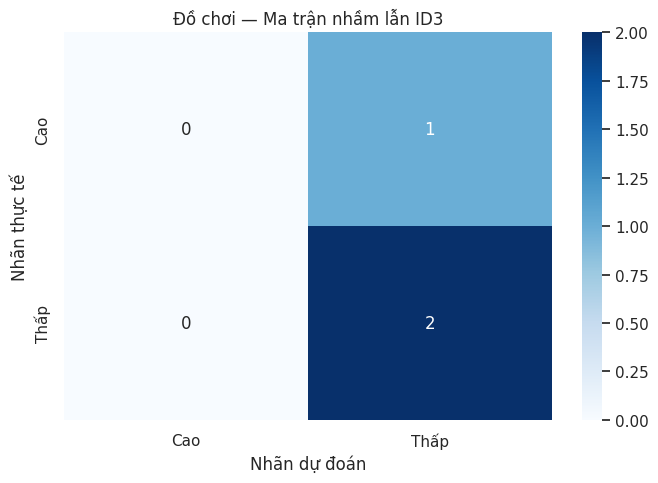

,Lớp,Số mẫu thực tế,Số dự đoán,Precision,Recall,F-measure
0,Cao,1,0,0.000000,0.0,0.0
1,Thấp,2,3,0.666667,1.0,0.8


F1 macro (trung bình F1 của các lớp): 0.4
Đồ chơi — Naïve Bayes


,Loại,Số màu,Kích thước,Chất liệu,Thực_tế,Dự_đoán
0,Búp bê,3,To,Cao su,Thấp,Thấp
1,Xếp hình,5,To,Nhựa PP,Thấp,Cao
2,Điều khiển,3,Vừa,Cao su,Cao,Thấp


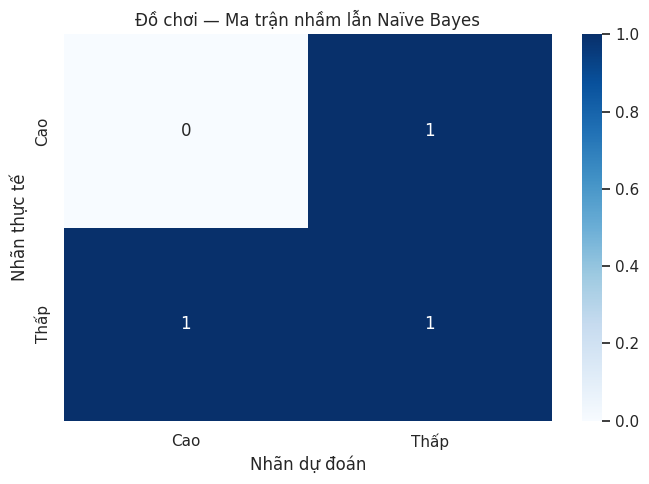

,Lớp,Số mẫu thực tế,Số dự đoán,Precision,Recall,F-measure
0,Cao,1,1,0.0,0.0,0.0
1,Thấp,2,2,0.5,0.5,0.5


F1 macro (trung bình F1 của các lớp): 0.25
Cảm xúc — Cây Gini theo PDF


,giảm,người,chuyển,yêu,vừa,đi,Thực_tế,Dự_đoán
0,0..5,6..10,0..5,11..20,6..10,0..5,xấu,tốt
1,0..5,0..5,6..10,0..5,11..20,>20,tốt,tốt
2,6..10,0..5,11..20,>20,6..10,6..10,bình thường,xấu
3,6..10,11..20,6..10,6..10,>20,0..5,tốt,tốt


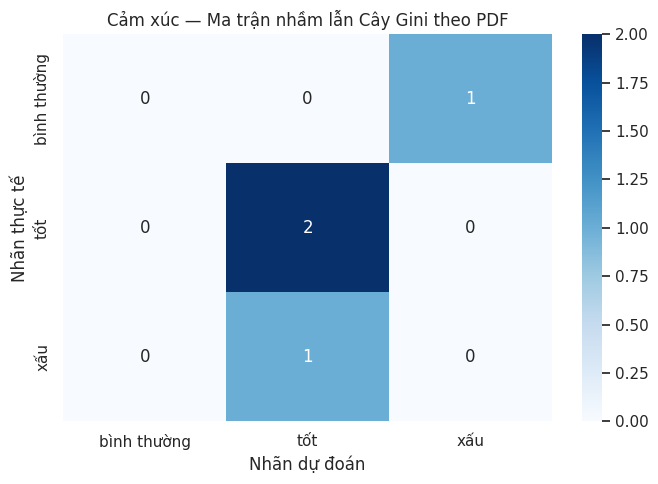

,Lớp,Số mẫu thực tế,Số dự đoán,Precision,Recall,F-measure
0,bình thường,1,0,0.000000,0.0,0.0
1,tốt,2,3,0.666667,1.0,0.8
2,xấu,1,1,0.000000,0.0,0.0


F1 macro (trung bình F1 của các lớp): 0.26666666666666666
Cảm xúc — Naïve Bayes


,giảm,người,chuyển,yêu,vừa,đi,Thực_tế,Dự_đoán
0,0..5,6..10,0..5,11..20,6..10,0..5,xấu,xấu
1,0..5,0..5,6..10,0..5,11..20,>20,tốt,tốt
2,6..10,0..5,11..20,>20,6..10,6..10,bình thường,bình thường
3,6..10,11..20,6..10,6..10,>20,0..5,tốt,tốt


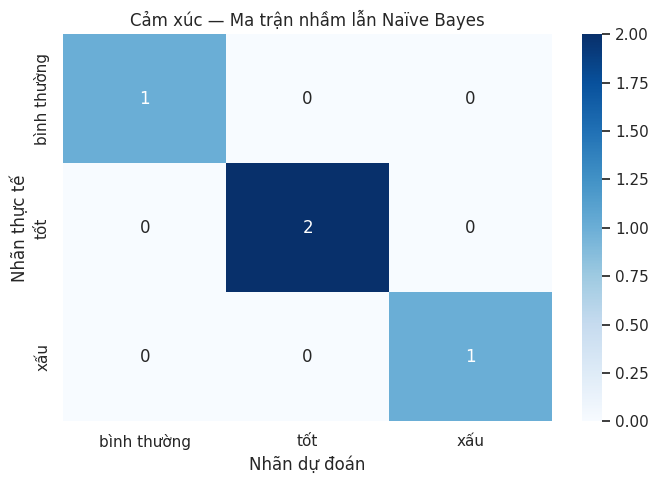

,Lớp,Số mẫu thực tế,Số dự đoán,Precision,Recall,F-measure
0,bình thường,1,1,1.0,1.0,1.0
1,tốt,2,2,1.0,1.0,1.0
2,xấu,1,1,1.0,1.0,1.0


F1 macro (trung bình F1 của các lớp): 1.0


,Bài,Mô hình,F1 macro
0,Đồ chơi,ID3,0.400000
1,Đồ chơi,Naïve Bayes,0.250000
2,Cảm xúc,Cây Gini theo PDF,0.266667
3,Cảm xúc,Naïve Bayes,1.000000


Đồ chơi: F1 macro cao nhất thuộc ID3 trên đúng các mẫu kiểm thử trong đề.
Cảm xúc: F1 macro cao nhất thuộc Naïve Bayes trên đúng các mẫu kiểm thử trong đề.
Các tập kiểm thử chỉ có 3 hoặc 4 mẫu; kết quả không chứng minh ưu thế trên dữ liệu khác.


In [3]:
print("Đặng Ngọc Hiếu - 6451071024")

results = []
for title, frame, test, actual, target, criterion, tree_name in [
        ("Đồ chơi",toys,toys_test,toys_actual,"Doanh số bán","entropy","ID3"),
        ("Cảm xúc",sentiment,sentiment_test,sentiment_actual,"Cảm xúc","gini","Cây Gini theo PDF")]:
    tree = build_tree(frame,target,criterion)
    predictions = {tree_name:[predict_tree(tree,row) for _,row in test.iterrows()],
        "Naïve Bayes":predict_bayes(frame,target,test)}
    classes = sorted(frame[target].unique())
    for model_name, predicted in predictions.items():
        print(title, "—", model_name)
        display(test.assign(Thực_tế=actual,Dự_đoán=predicted))
        cm = confusion_matrix(actual,predicted,labels=classes)
        plt.figure(figsize=(7,5))
        sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",xticklabels=classes,yticklabels=classes)
        plt.title(f"{title} — Ma trận nhầm lẫn {model_name}")
        plt.xlabel("Nhãn dự đoán")
        plt.ylabel("Nhãn thực tế")
        plt.tight_layout()
        plt.show()
        plt.close()
        precision,recall,_,support = precision_recall_fscore_support(
            actual,predicted,labels=classes,zero_division=0)
        denominator = precision+recall
        f_measure = np.divide(2*precision*recall,denominator,
            out=np.zeros_like(denominator),where=denominator!=0)
        table = pd.DataFrame({"Lớp":classes,"Số mẫu thực tế":support,
            "Số dự đoán":[predicted.count(label) for label in classes],
            "Precision":precision,"Recall":recall,"F-measure":f_measure})
        display(table)
        print("F1 macro (trung bình F1 của các lớp):", f_measure.mean())
        results.append({"Bài":title,"Mô hình":model_name,"F1 macro":f_measure.mean()})
comparison = pd.DataFrame(results)
display(comparison)
for title, group in comparison.groupby("Bài",sort=False):
    best = group.loc[group["F1 macro"].eq(group["F1 macro"].max()),"Mô hình"]
    print(f"{title}: F1 macro cao nhất thuộc {', '.join(best)} trên đúng các mẫu kiểm thử trong đề.")
print("Các tập kiểm thử chỉ có 3 hoặc 4 mẫu; kết quả không chứng minh ưu thế trên dữ liệu khác.")
